# Archived coursework — original outputs
**Not rerun:** the source workbook `invoices - updated.xlsx` was not supplied and could not be recovered from the notebook outputs. Saved outputs below come from the original coursework, not the corrected portfolio run. They cannot be independently verified without the workbook.

This notebook is retained as evidence of the original methods. Predictive results are exploratory: categorical encoders are fitted before splitting; several methods are compared on the same test set; the ANN validation subset shares preprocessing fitted to the larger training set. Feature availability and chronological ordering also require checking against the source data before claims of forecasting or leakage-free performance.


In [2]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.feature_selection import RFE
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler


df = pd.read_excel('invoices - updated.xlsx')

In [3]:
df.head()

,tax_number,invoice_number,issue_date,collection_type,invoice_sub_type,invoice_category,invoice_discount_amount,invoice_tax_amount,buyer_identification,buyer_name,days_overdue,expected_payment_amount
0,120985374,T7OPZRYKM,1708014393,CREDIT,EXPORT,GENERAL_SALES,0.0,106.23,NaN,NaN,0,649.84
1,748392615,2BFOJ03E5,1749262653,CASH,LOCAL,INCOME,0.0,135.67,NaN,NaN,12,1437.72
2,382915476,MD4FU4NP1,1642622798,CASH,LOCAL,INCOME,0.0,96.66,NaN,NaN,12,1216.49
3,382915476,V4IUP8311,1706758339,CREDIT,EXPORT,SPECIAL_SALES,0.0,81.02,NaN,NaN,0,1817.24
4,382915476,VURP4E9V3,1694894569,CREDIT,AREA_OF_DEVELOPMENT,INCOME,0.0,120.53,NaN,NaN,0,1244.63


In [4]:
df = df.drop(columns = ['buyer_identification', 'buyer_name'])
df.head()

,tax_number,invoice_number,issue_date,collection_type,invoice_sub_type,invoice_category,invoice_discount_amount,invoice_tax_amount,days_overdue,expected_payment_amount
0,120985374,T7OPZRYKM,1708014393,CREDIT,EXPORT,GENERAL_SALES,0.0,106.23,0,649.84
1,748392615,2BFOJ03E5,1749262653,CASH,LOCAL,INCOME,0.0,135.67,12,1437.72
2,382915476,MD4FU4NP1,1642622798,CASH,LOCAL,INCOME,0.0,96.66,12,1216.49
3,382915476,V4IUP8311,1706758339,CREDIT,EXPORT,SPECIAL_SALES,0.0,81.02,0,1817.24
4,382915476,VURP4E9V3,1694894569,CREDIT,AREA_OF_DEVELOPMENT,INCOME,0.0,120.53,0,1244.63


In [5]:
df.head()

,tax_number,invoice_number,issue_date,collection_type,invoice_sub_type,invoice_category,invoice_discount_amount,invoice_tax_amount,days_overdue,expected_payment_amount
0,120985374,T7OPZRYKM,1708014393,CREDIT,EXPORT,GENERAL_SALES,0.0,106.23,0,649.84
1,748392615,2BFOJ03E5,1749262653,CASH,LOCAL,INCOME,0.0,135.67,12,1437.72
2,382915476,MD4FU4NP1,1642622798,CASH,LOCAL,INCOME,0.0,96.66,12,1216.49
3,382915476,V4IUP8311,1706758339,CREDIT,EXPORT,SPECIAL_SALES,0.0,81.02,0,1817.24
4,382915476,VURP4E9V3,1694894569,CREDIT,AREA_OF_DEVELOPMENT,INCOME,0.0,120.53,0,1244.63


## 1. Statistical Approaches 

Here I treat the data as a simple time series to get a baseline understanding of the trend in expected payments.


In [6]:
# in order to be able to start with statistical approch.
# i need to conver issue date to datetime format
df['issue_date'] = pd.to_datetime(df['issue_date'], unit = 's')

timeseries = df.set_index('issue_date')['expected_payment_amount'].sort_index()
print(timeseries)

issue_date
2021-12-31 21:00:18     942.15
2021-12-31 21:03:57     940.60
2021-12-31 21:07:50    1502.66
2021-12-31 21:18:50    1216.30
2021-12-31 21:18:56    2706.97
                        ...   
2025-12-31 20:40:11    1233.49
2025-12-31 20:40:11    1493.36
2025-12-31 20:40:59    2422.95
2025-12-31 20:42:42     841.14
2025-12-31 20:43:14    3437.29
Name: expected_payment_amount, Length: 532057, dtype: float64


Simple Moving Average

In [7]:
# i will try different smoothin average k values. 
SMA_10 = timeseries.rolling(window=10).mean()
SMA_55 = timeseries.rolling(window=55).mean()
SMA_95 = timeseries.rolling(window=95).mean()

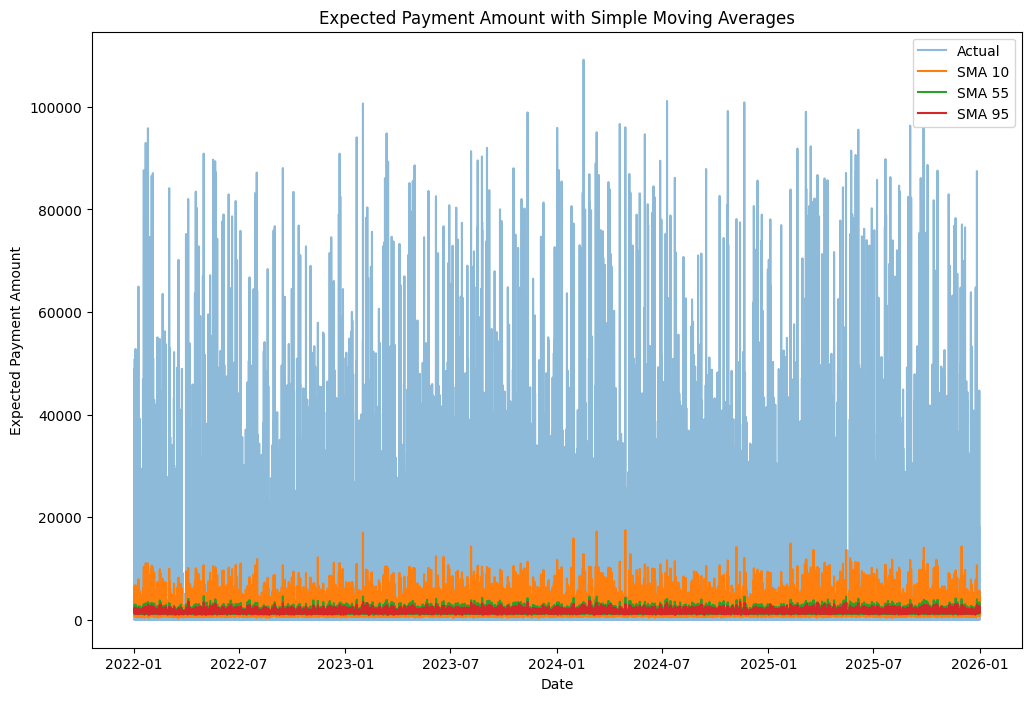

In [8]:
#Plotting them against the actual time series
plt.figure(figsize=(12,8))
plt.plot(timeseries, label='Actual', alpha=0.5)
plt.plot(SMA_10, label='SMA 10')
plt.plot(SMA_55, label='SMA 55')
plt.plot(SMA_95, label='SMA 95')
plt.title("Expected Payment Amount with Simple Moving Averages")
plt.ylabel("Expected Payment Amount")
plt.xlabel("Date")
plt.legend()
plt.show()

Exponential smoothing

In [9]:
# trying different alphas for exponential smoothing
exp_smooth_3 = timeseries.ewm(alpha=0.3).mean()
exp_smooth_6 = timeseries.ewm(alpha=0.6).mean()
exp_smooth_9 = timeseries.ewm(alpha=0.9).mean()

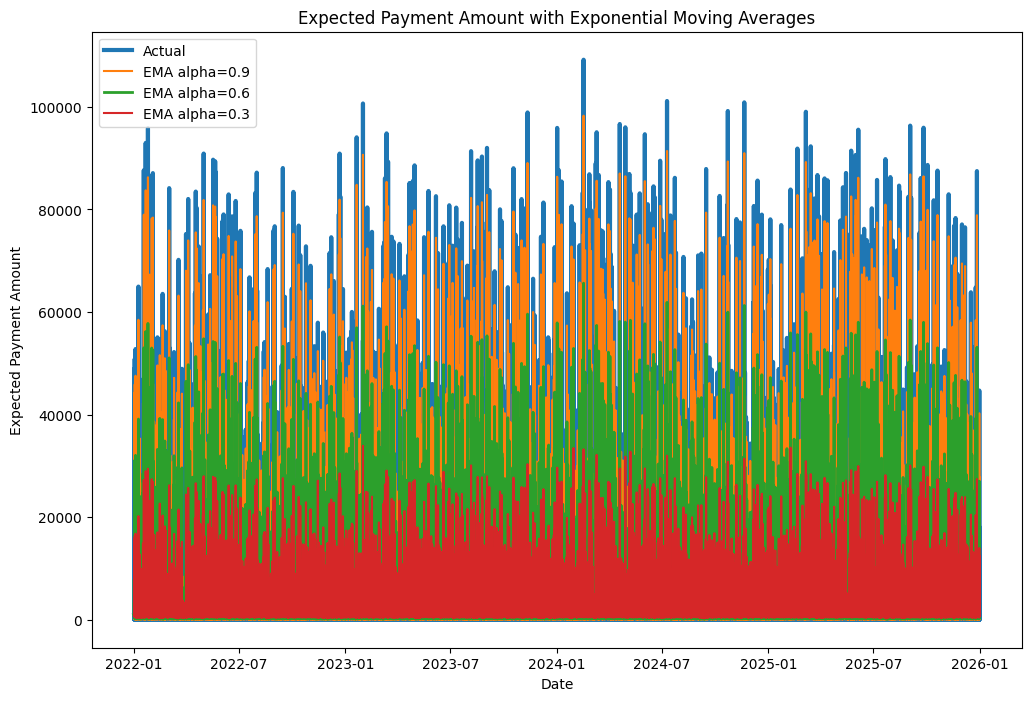

In [10]:
plt.figure(figsize=(12,8))
plt.plot(timeseries, label='Actual', linewidth=3)
plt.plot(exp_smooth_9, label='EMA alpha=0.9', linewidth=1.5)
plt.plot(exp_smooth_6, label='EMA alpha=0.6', linewidth=2.0)
plt.plot(exp_smooth_3, label='EMA alpha=0.3', linewidth=1.5)

plt.xlabel("Date")
plt.ylabel("Expected Payment Amount")
plt.title('Expected Payment Amount with Exponential Moving Averages')
plt.legend()
plt.show()

## 2. Data Preparation for Supervised Learning

- Remove non-useful columns (buyer fields) and unique identifiers  
- Encode categorical features (Label Encoding)  
- Split into train/test  


Feature Selection

In [11]:
# Drop unique identifiers that don't add predictive value for general regression
df = df.drop(columns = ['tax_number', 'invoice_number','issue_date'])
df.head()

,collection_type,invoice_sub_type,invoice_category,invoice_discount_amount,invoice_tax_amount,days_overdue,expected_payment_amount
0,CREDIT,EXPORT,GENERAL_SALES,0.0,106.23,0,649.84
1,CASH,LOCAL,INCOME,0.0,135.67,12,1437.72
2,CASH,LOCAL,INCOME,0.0,96.66,12,1216.49
3,CREDIT,EXPORT,SPECIAL_SALES,0.0,81.02,0,1817.24
4,CREDIT,AREA_OF_DEVELOPMENT,INCOME,0.0,120.53,0,1244.63


In [12]:
le = LabelEncoder()
encode = ['collection_type', 'invoice_sub_type', 'invoice_category']

for i in encode:
    df[i] = le.fit_transform(df[i]) # Encoding categorical data

X = df.drop('expected_payment_amount', axis=1)
y = df['expected_payment_amount']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## 3. Feature Selection Experiments (with Linear Regression)

I test feature selection methods to see if performance improves before trying other models.


### Linear Regression (Feature Selection Tests)

In [13]:
# first, im going to try forward selection with linear regression
lr = LinearRegression()

sfs = SequentialFeatureSelector(lr, n_features_to_select=3, direction='forward')
sfs.fit(X_train, y_train)

X_train_sfs = sfs.transform(X_train)
X_test_sfs = sfs.transform(X_test)

lr.fit(X_train_sfs, y_train)
y_pred_sfs = lr.predict(X_test_sfs)

print("Selected Features:", sfs.get_feature_names_out())
print("MAE:", mean_absolute_error(y_test, y_pred_sfs))
print("MSE:", mean_squared_error(y_test, y_pred_sfs))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_sfs)))
print("R²:", r2_score(y_test, y_pred_sfs))

Selected Features: ['collection_type' 'invoice_tax_amount' 'days_overdue']
MAE: 490.7292278429062
MSE: 385593.47168174345
RMSE: 620.9617312538217
R²: 0.953950930293518


In [14]:
# now im going to try SelectKBest with linear regression
skb = SelectKBest(f_regression, k=3)
skb.fit(X_train, y_train)


X_train_skb = skb.transform(X_train)
X_test_skb = skb.transform(X_test)

lr.fit(X_train_skb, y_train)
y_pred_skb = lr.predict(X_test_skb)

print("Selected Features (Indices):", skb.get_support(indices=True))
print("MAE:", mean_absolute_error(y_test, y_pred_skb))
print("MSE:", mean_squared_error(y_test, y_pred_skb))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_skb)))
print("R²:", r2_score(y_test, y_pred_skb))

Selected Features (Indices): [3 4 5]
MAE: 776.7778940171609
MSE: 1108727.9310558161
RMSE: 1052.9615050208702
R²: 0.8675914051136924


## 4. Machine Learning Model (Decision Tree Regression)

After feature selection experiments, I train a Decision Tree Regressor and evaluate it using MAE/MSE/RMSE/R².


### Decision Tree Regression

In [15]:
dt = DecisionTreeRegressor(random_state=42)
sfs_dt = SequentialFeatureSelector(dt, n_features_to_select=3, direction='forward')
sfs_dt.fit(X_train, y_train)


X_train_sfs_dt = sfs_dt.transform(X_train)
X_test_sfs_dt = sfs_dt.transform(X_test)

dt.fit(X_train_sfs_dt, y_train)
y_pred = dt.predict(X_test_sfs_dt)


print("Selected Features:", sfs_dt.get_feature_names_out())
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R²:", r2_score(y_test, y_pred))


Selected Features: ['collection_type' 'invoice_tax_amount' 'days_overdue']
MAE: 321.041232587508
MSE: 217810.25701155697
RMSE: 466.70146454833093
R²: 0.9739882533172388


In [16]:
dt.fit(X_train_skb, y_train)
y_pred = dt.predict(X_test_skb)

print("Selected Features (Indices):", skb.get_support(indices=True))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R²:", r2_score(y_test, y_pred))

Selected Features (Indices): [3 4 5]
MAE: 480.7399025045102
MSE: 601548.9722918533
RMSE: 775.5958820751006
R²: 0.9281606858225195


## 5. Deep Learning Models

I prepare the data as sequences and train:
- **RNN** (SimpleRNN)  
- **LSTM**  

Evaluation includes MSE and R² for comparison.


### 5.1 Sequence Preparation

In [17]:
# RNN to predict expected payment amount

rnn = pd.read_excel('invoices - updated.xlsx')

rnn = rnn.drop(columns=['tax_number', 'invoice_number', 'buyer_identification','buyer_name'])

In [18]:
rnn['issue_date'] = pd.to_datetime(rnn['issue_date'], unit = 's')
rnn.index = rnn['issue_date']
rnn.drop(['issue_date'], axis=1, inplace=True)
rnn.sort_index(inplace=True)

rnn = rnn.iloc[100000:]

In [19]:
X = rnn.drop(['expected_payment_amount'],axis=1)
y = rnn['expected_payment_amount']

#Encoding categorical variables

le = LabelEncoder()

to_encode = ['collection_type', 'invoice_sub_type', 'invoice_category']

for i in to_encode:
    X[i] = le.fit_transform(X[i])


train_size = int(len(X) * 0.7)

X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]


In [20]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler(feature_range=(0, 1))

X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

In [21]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, Dense, Dropout

def create_sequences(X, y, timesteps):
    X_seq, y_seq = [], []
    for i in range(len(X) - timesteps):
        X_seq.append(X[i:i+timesteps])
        y_seq.append(y[i+timesteps])
    return np.array(X_seq), np.array(y_seq)

c:\Users\MAA\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\export\tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


In [22]:
timesteps = 10

X_train_seq, y_train_seq = create_sequences(X_train, y_train, timesteps)
X_test_seq,  y_test_seq  = create_sequences(X_test,  y_test,  timesteps)

C:\Users\MAA\AppData\Local\Temp\ipykernel_6848\3671584638.py:8: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  y_seq.append(y[i+timesteps])


In [23]:
model = Sequential([
    SimpleRNN(
        units=50,
        activation='tanh',
        input_shape=(timesteps, X_train_seq.shape[2])
    ),
    Dense(1)
])

c:\Users\MAA\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [24]:
model.compile(optimizer='adam',loss='mse')

In [25]:
model.fit(X_train_seq,y_train_seq, epochs=30,batch_size=16,validation_split=0.1,verbose=1)


Epoch 1/30
17012/17012 ━━━━━━━━━━━━━━━━━━━━ 31s 2ms/step - loss: 10054177.0000 - val_loss: 9095018.0000
Epoch 2/30
17012/17012 ━━━━━━━━━━━━━━━━━━━━ 33s 2ms/step - loss: 8874326.0000 - val_loss: 8445951.0000
Epoch 3/30
17012/17012 ━━━━━━━━━━━━━━━━━━━━ 30s 2ms/step - loss: 8543097.0000 - val_loss: 8330091.5000
Epoch 4/30
17012/17012 ━━━━━━━━━━━━━━━━━━━━ 30s 2ms/step - loss: 8496490.0000 - val_loss: 8318363.5000
Epoch 5/30
17012/17012 ━━━━━━━━━━━━━━━━━━━━ 33s 2ms/step - loss: 8491828.0000 - val_loss: 8317196.0000
Epoch 6/30
17012/17012 ━━━━━━━━━━━━━━━━━━━━ 33s 2ms/step - loss: 8491299.0000 - val_loss: 8317004.5000
Epoch 7/30
17012/17012 ━━━━━━━━━━━━━━━━━━━━ 34s 2ms/step - loss: 8491229.0000 - val_loss: 8316981.5000
Epoch 8/30
17012/17012 ━━━━━━━━━━━━━━━━━━━━ 33s 2ms/step - loss: 8491216.0000 - val_loss: 8316979.0000
Epoch 9/30
17012/17012 ━━━━━━━━━━━━━━━━━━━━ 33s 2ms/step - loss: 8491204.0000 - val_loss: 8316977.0000
Epoch 10/30
17012/17012 ━━━━━━━━━━━━━━━━━━━━ 33s 2ms/step - loss: 849120

In [27]:
y_predictions_rnn = model.predict(X_test_seq).ravel()

print("RNN MSE:", mean_squared_error(y_test_seq, y_predictions_rnn))
print("RNN R²:", r2_score(y_test_seq, y_predictions_rnn))

4051/4051 ━━━━━━━━━━━━━━━━━━━━ 4s 912us/step
RNN MSE: 9301343.974891182
RNN R²: -0.00011365198860491255


### 5.3 LSTM Model

In [ ]:
lstm_model = Sequential([
    LSTM(
        units=64,
        activation='tanh',
        input_shape=(timesteps, X_train_seq.shape[2])
    ),
    Dropout(0.2),
    Dense(1)
])

In [ ]:
lstm_model.compile(optimizer='adam',loss='mse')

In [ ]:
memory = lstm_model.fit(
    X_train_seq,
    y_train_seq,
    epochs=30,
    batch_size=16,
    validation_split=0.1,
    verbose=1
)

Epoch 1/30
17012/17012 ━━━━━━━━━━━━━━━━━━━━ 29s 2ms/step - loss: 9898326.0000 - val_loss: 8868741.0000
Epoch 2/30
17012/17012 ━━━━━━━━━━━━━━━━━━━━ 29s 2ms/step - loss: 8720776.0000 - val_loss: 8370979.0000
Epoch 3/30
17012/17012 ━━━━━━━━━━━━━━━━━━━━ 28s 2ms/step - loss: 8519898.0000 - val_loss: 8321316.0000
Epoch 4/30
17012/17012 ━━━━━━━━━━━━━━━━━━━━ 29s 2ms/step - loss: 8502499.0000 - val_loss: 8317469.5000
Epoch 5/30
17012/17012 ━━━━━━━━━━━━━━━━━━━━ 28s 2ms/step - loss: 8503539.0000 - val_loss: 8317074.5000
Epoch 6/30
17012/17012 ━━━━━━━━━━━━━━━━━━━━ 29s 2ms/step - loss: 8500494.0000 - val_loss: 8317048.0000
Epoch 7/30
17012/17012 ━━━━━━━━━━━━━━━━━━━━ 28s 2ms/step - loss: 8501550.0000 - val_loss: 8317011.0000
Epoch 8/30
17012/17012 ━━━━━━━━━━━━━━━━━━━━ 28s 2ms/step - loss: 8500177.0000 - val_loss: 8317005.5000
Epoch 9/30
17012/17012 ━━━━━━━━━━━━━━━━━━━━ 29s 2ms/step - loss: 8500811.0000 - val_loss: 8317026.0000
Epoch 10/30
17012/17012 ━━━━━━━━━━━━━━━━━━━━ 29s 2ms/step - loss: 8501345

In [ ]:
y_predictions_lstm = lstm_model.predict(X_test_seq).ravel()

print("LSTM MSE:", mean_squared_error(y_test_seq, y_predictions_lstm))
print("LSTM R²:", r2_score(y_test_seq, y_predictions_lstm))

4051/4051 ━━━━━━━━━━━━━━━━━━━━ 6s 1ms/step
LSTM MSE: 9301772.492324647
LSTM R²: -0.00015972771018679666
